# 6 - Explore extracted features

This code is to explore the feature space of the embeddings extracted from the H&E WSIs using foundation models. It does not generate any data that is used downstreatm

In [ ]:
import glob
import os
import numpy as np
from PIL import Image
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

from utils import set_seed, load_features_from_csv

In [58]:
stain_alg = 'original'

In [59]:
def load_data(geneset, feat_extr, segment, test=False,root_path =''):
    
    if test:
        suffix='_TEST'
    else:
        suffix=''
    print(geneset)
    print(feat_extr)
    feat_file= f'{feat_extr}-{segment}_features.csv'
    print(feat_file)
    truth_file=f'{geneset.lower()}_{segment[:-1].lower()}_raw{suffix}.csv'
    print(truth_file)

    # 1. read in outcomes
    outcome_df = pd.read_csv(os.path.join(root_path,'truthlabels',truth_file))
    outcome_df = outcome_df.set_index('ROI_ID')
    ## doing this to check later if the first gene is NA
    sig_name = outcome_df.columns[0]
    
    print(f"feature file: {feat_file}")
    image_names, feature_matrix = load_features_from_csv(os.path.join(root_path,'features','stainnorm',stain_alg,feat_file))

    """if i'm reading features from a file then have to get metadata from image names"""

    patch_metadata = pd.DataFrame([x.replace('.png','').split('_') for x in image_names],columns=['name', 'LEAP_ID', 'Segment','ROI_num', 'x', 'y'])
    patch_metadata = patch_metadata.set_index('name')
    patch_metadata = patch_metadata.filter(items=['LEAP_ID'])
    # remove patches that we don't have both features and outcomes

    merged_df = patch_metadata.join(outcome_df, how='left')

    mask = ~merged_df[sig_name].isna()
    feature_matrix_clean = feature_matrix[mask.values]
    merged_df = merged_df.dropna(subset=[sig_name])

    return feature_matrix_clean, merged_df


In [60]:
def displayImgsWithLabel(patches, clabels,label_to_show, images_per_row=4):
    # Assuming labels is the array containing cluster labels for each patch
    label_1_indices = [i for i, clabel in enumerate(clabels) if clabel == label_to_show]
    label_1_patches = [patches[i] for i in label_1_indices]

    # Calculate the number of rows needed
    num_rows = (len(label_1_patches) + images_per_row - 1) // images_per_row

    plt.figure(figsize=(15, 1.5*num_rows))

    for i, patch in enumerate(label_1_patches):
        plt.subplot(num_rows, images_per_row, i + 1)
        plt.imshow(patch)  # Assuming patches are in CxHxW format
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
GENERATE_FEATURES = False
root_path = '..//data'
num_samples = 500 

# Get Image Features

patches = []
for path in patch_paths:
    with Image.open(path).convert('RGB') as img:
        patches.append(img.copy())  # Copy image data to avoid keeping the file open

In [77]:
feat_extr = 'combined'
segment='CD45+'

In [78]:
_, labels_hvg =load_data('HVGs', feat_extr, segment, test=False,root_path=root_path)
_, labels_svg =load_data('SVGs', feat_extr, segment, test=False,root_path=root_path)
_, labels_pan =load_data('Panel', feat_extr, segment, test=False,root_path=root_path)

HVGs
combined
combined-CD45+_features.csv
hvgs_cd45_raw.csv
feature file: combined-CD45+_features.csv
SVGs
combined
combined-CD45+_features.csv
svgs_cd45_raw.csv
feature file: combined-CD45+_features.csv
Panel
combined
combined-CD45+_features.csv
panel_cd45_raw.csv
feature file: combined-CD45+_features.csv


In [79]:
labels_all = labels_pan.join(labels_hvg.drop(columns=['LEAP_ID']),rsuffix='_2')
labels_all = labels_all.join(labels_svg.drop(columns=['LEAP_ID']),rsuffix='_2')
labels_all.shape

(1287, 115)

In [80]:
labels_all = labels_all.loc[:, ~labels_all.columns.str.contains('_2')]
labels_all.head()

,LEAP_ID,CD274,CXCL9,IFNG,BCL2,CD3D,CD8A,CD4,FOXP3,CD68,...,TARP,TAPBP,TENT5C,RPS20,HLA-B,REPS2,ST6GALNAC3,HLA-E,APOE,NDOR1
name,,,,,,,,,,,,,,,,,,,,,
DSP-1001660013337-F-A04.dcc,LEAP014,0.693147,2.397895,0.693147,0.693147,1.098612,1.386294,1.098612,0.693147,0.693147,...,0.693147,0.693147,1.098612,2.708050,4.060443,0.693147,0.693147,2.708050,1.609438,0.693147
DSP-1001660008695-A-A02.dcc,LEAP002,1.098612,1.609438,1.098612,0.693147,1.386294,0.693147,1.098612,0.693147,1.609438,...,0.693147,1.098612,0.693147,4.382027,4.442651,0.693147,0.693147,2.890372,2.772589,0.693147
DSP-1001660008695-A-A04.dcc,LEAP002,1.098612,2.302585,0.693147,0.693147,0.693147,1.098612,0.693147,1.098612,0.693147,...,0.693147,2.079442,1.098612,4.779123,4.465908,0.693147,0.693147,3.091042,2.197225,0.693147
DSP-1001660008695-A-A06.dcc,LEAP002,1.098612,3.295837,1.609438,1.609438,1.386294,1.945910,1.098612,0.693147,1.791759,...,1.609438,1.945910,1.609438,4.941642,5.111988,1.098612,0.693147,3.688879,2.890372,0.693147
DSP-1001660008695-A-A08.dcc,LEAP002,0.693147,2.302585,1.386294,1.386294,1.609438,0.693147,0.693147,0.693147,1.791759,...,1.791759,1.791759,0.693147,4.454347,4.691348,0.693147,0.693147,3.091042,2.564949,0.693147


In [81]:
feat_file= f'{feat_extr}-{segment}_features.csv'
feat_path=os.path.join(root_path,'features','stainnorm',stain_alg)
image_names, feature_matrix = load_features_from_csv(os.path.join(feat_path,feat_file))

In [82]:
patch_metadata = pd.DataFrame([x.replace('.png','').split('_') for x in image_names],columns=['name', 'LEAP_ID', 'Segment','ROI_num', 'x', 'y'])
patch_metadata = patch_metadata.set_index('name')
#patch_metadata = patch_metadata.filter(items=['LEAP_ID'])
# remove patches that we don't have both features and outcomes
patch_metadata

,LEAP_ID,Segment,ROI_num,x,y
name,,,,,
DSP-1001660013337-F-A04.dcc,LEAP014,CD45+,ROI2,7719,673
DSP-1001660008695-A-A02.dcc,LEAP002,CD45+,ROI1,6188,13576
DSP-1001660008695-A-A04.dcc,LEAP002,CD45+,ROI2,5811,13756
DSP-1001660008695-A-A06.dcc,LEAP002,CD45+,ROI3,2579,10969
DSP-1001660008695-A-A08.dcc,LEAP002,CD45+,ROI4,6753,13371
...,...,...,...,...,...
DSP-1001660023970-F-B07.dcc,LEAP148,CD45+,ROI10,6483,10100
DSP-1001660023970-F-B09.dcc,LEAP148,CD45+,ROI11,6819,10069
DSP-1001660023970-F-B10.dcc,LEAP148,CD45+,ROI12,7108,10365


In [83]:
labels_all

,LEAP_ID,CD274,CXCL9,IFNG,BCL2,CD3D,CD8A,CD4,FOXP3,CD68,...,TARP,TAPBP,TENT5C,RPS20,HLA-B,REPS2,ST6GALNAC3,HLA-E,APOE,NDOR1
name,,,,,,,,,,,,,,,,,,,,,
DSP-1001660013337-F-A04.dcc,LEAP014,0.693147,2.397895,0.693147,0.693147,1.098612,1.386294,1.098612,0.693147,0.693147,...,0.693147,0.693147,1.098612,2.708050,4.060443,0.693147,0.693147,2.708050,1.609438,0.693147
DSP-1001660008695-A-A02.dcc,LEAP002,1.098612,1.609438,1.098612,0.693147,1.386294,0.693147,1.098612,0.693147,1.609438,...,0.693147,1.098612,0.693147,4.382027,4.442651,0.693147,0.693147,2.890372,2.772589,0.693147
DSP-1001660008695-A-A04.dcc,LEAP002,1.098612,2.302585,0.693147,0.693147,0.693147,1.098612,0.693147,1.098612,0.693147,...,0.693147,2.079442,1.098612,4.779123,4.465908,0.693147,0.693147,3.091042,2.197225,0.693147
DSP-1001660008695-A-A06.dcc,LEAP002,1.098612,3.295837,1.609438,1.609438,1.386294,1.945910,1.098612,0.693147,1.791759,...,1.609438,1.945910,1.609438,4.941642,5.111988,1.098612,0.693147,3.688879,2.890372,0.693147
DSP-1001660008695-A-A08.dcc,LEAP002,0.693147,2.302585,1.386294,1.386294,1.609438,0.693147,0.693147,0.693147,1.791759,...,1.791759,1.791759,0.693147,4.454347,4.691348,0.693147,0.693147,3.091042,2.564949,0.693147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
DSP-1001660023970-F-B07.dcc,LEAP148,1.098612,2.079442,0.693147,2.397895,1.609438,2.708050,2.564949,0.693147,2.708050,...,1.609438,2.079442,1.609438,4.007333,5.493061,1.098612,0.693147,4.007333,4.219508,0.693147
DSP-1001660023970-F-B09.dcc,LEAP148,1.609438,5.370638,2.708050,4.934474,4.564348,5.075174,5.023881,3.332205,4.997212,...,3.555348,5.176150,3.891820,7.160069,8.129175,3.135494,3.332205,6.959399,5.863631,3.258097
DSP-1001660023970-F-B10.dcc,LEAP148,1.945910,2.639057,1.945910,4.553877,3.433987,3.761200,3.178054,2.197225,3.912023,...,3.178054,4.248495,3.295837,6.496775,7.249926,2.197225,2.639057,6.095825,4.605170,2.708050


In [85]:
labels_all = labels_all.drop(columns='LEAP_ID')
merged_df = patch_metadata.join(labels_all, how='left')
merged_df.shape

(1417, 109)

In [86]:
mask = ~merged_df['CD274'].isna()
mask.shape

(1417,)

In [87]:


np.random.seed(42)
subset_indices = np.random.choice(len(feature_matrix), num_samples, replace=False)
subset_names = [image_names[i] for i in subset_indices] #merged_df.iloc[subset_indices].index


In [88]:
len(subset_names)

500

In [89]:

subset_patches = []
for patch in subset_names:
    #print(patch)
    # read in patch
    # add patch to subset_patches
    with Image.open(os.path.join(root_path,'patches','10x','original',segment,patch)) as img:
        subset_patches.append(img.copy())

In [90]:
subset_features = feature_matrix[subset_indices]
subset_features.shape

(500, 5120)

# TSNE

In [91]:
from sklearn.manifold import TSNE
import matplotlib.cm as cm
import seaborn as sns

In [92]:
tsne = TSNE(n_components=2, perplexity=10, random_state=42)
X_tsne = tsne.fit_transform(feature_matrix)
tsne_df = pd.DataFrame(X_tsne, columns=['TSNE1','TSNE2'])
tsne_df['LEAP_ID'] = merged_df['LEAP_ID'].values

In [93]:
leaps = sorted(list(tsne_df['LEAP_ID'].unique()))

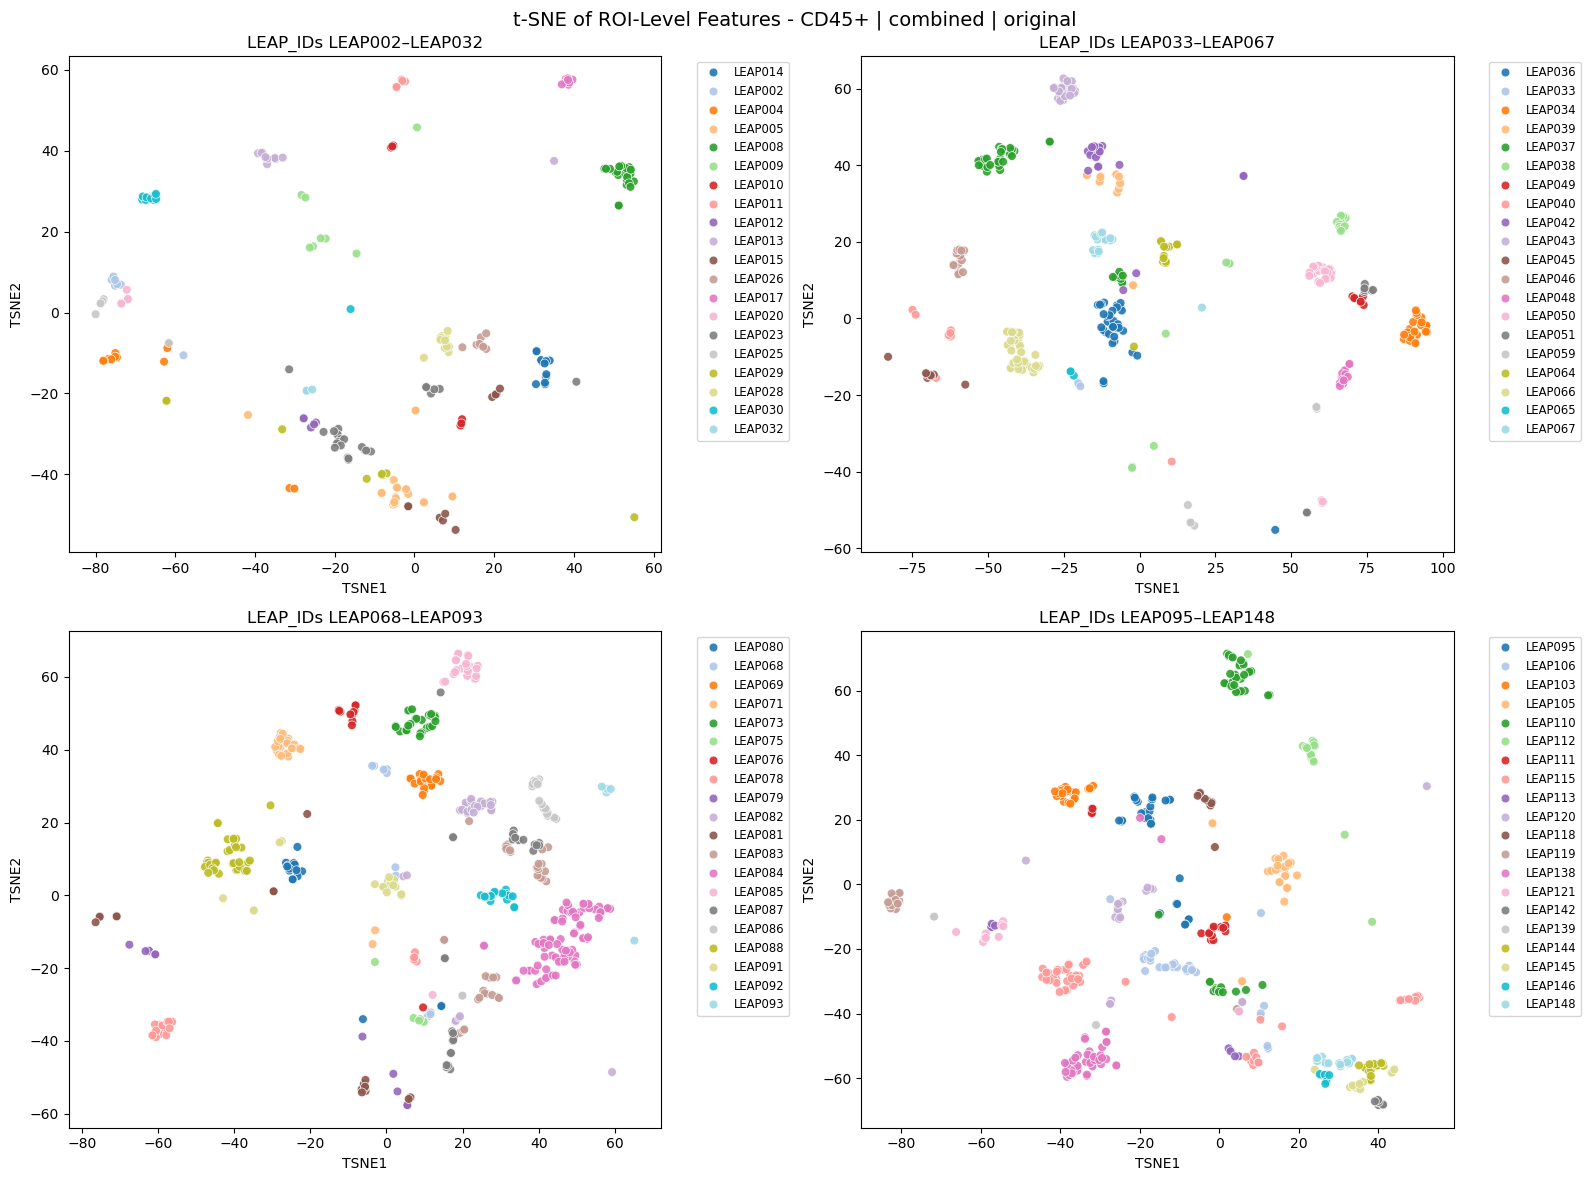

In [94]:

# create 4 subplots (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, ax in enumerate(axes):
    start = i * 20
    end = min(start + 20,len(leaps))
    leap_subset = leaps[start:end]
    sub_df = tsne_df[tsne_df['LEAP_ID'].isin(leap_subset)]

    sns.scatterplot(
        x='TSNE1', y='TSNE2',
        hue='LEAP_ID',
        data=sub_df,
        palette='tab20',
        ax=ax,
        s=40, alpha=0.9
    )
    ax.set_title(f'LEAP_IDs {leaps[start]}–{leaps[end-1]}')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')

plt.suptitle(f't-SNE of ROI-Level Features - {segment} | {feat_extr} | {stain_alg}', fontsize=14)
plt.tight_layout()
plt.show()

# Find Optimal # Clusters

In [ ]:
# Assuming `features` is the array of feature vectors extracted earlier
inertia = []
k_values = range(2, 30)  # Testing k values from 1 to 10

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(subset_features)
    inertia.append(kmeans.inertia_)  # Inertia is the sum of squared distances to the nearest cluster center


In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(k_values, inertia, 'bo-', markersize=8)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Plot for Optimal k')
plt.grid(True)
plt.show()
# Save the plot as an image file
#plt.savefig(os.path.join(root_path,'elbow_plot1.png'), format='png', dpi=300)  # Save as a PNG file with 300 dpi resolution

# Optionally, you can close the plot if you do not want to display it
#plt.close()


In [ ]:
from sklearn.metrics import silhouette_score

sil_scores = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42).fit(subset_features)
    labels = kmeans.labels_
    sil_scores.append(silhouette_score(subset_features, labels))

# Plot the silhouette scores
plt.figure(figsize=(8, 6))
plt.plot(k_values, sil_scores, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Optimal k')
plt.grid(True)
plt.show()

#plt.savefig(os.path.join(root_path,'silhouette_plot.png'), format='png', dpi=300)
#plt.close()


In [ ]:
from sklearn.metrics import davies_bouldin_score

db_scores = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42).fit(subset_features)
    labels = kmeans.labels_
    db_scores.append(davies_bouldin_score(subset_features, labels))

# Plot the Davies-Bouldin Index
plt.figure(figsize=(8, 6))
plt.plot(k_values, db_scores, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin Index for Optimal k')
plt.grid(True)
plt.show()


In [ ]:
# Find the index of the highest silhouette score
max_sil_index = sil_scores.index(max(sil_scores))
print(f"The highest silhouette score is at index {max_sil_index}, which corresponds to k = {max_sil_index + 2}")


In [ ]:
# Find the index of the lowest db score
min_db_index = db_scores.index(min(db_scores))
print(f"The lowest db score is at index {min_db_index}, which corresponds to k = {min_db_index + 2}")

# Cluster

In [ ]:
# Choose the number of clusters (k) you want to use
k = max_sil_index + min(k_values) 
k=16
print(k)
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(subset_features)

# The labels for each image patch
clabels = kmeans.labels_

In [ ]:
pca = PCA(n_components=2)  # Reduce to 2 dimensions for visualization
features_2d = pca.fit_transform(subset_features)

In [ ]:


plt.figure(figsize=(10, 8))
plt.scatter(features_2d[:, 0], features_2d[:, 1], c=clabels, cmap='viridis')
plt.colorbar()
plt.title("K-Means Clustering of Image Patches")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

# Visual Sanity Check Clusters

In [ ]:
for i in range(k):
    print("Cluster: ",i)
    displayImgsWithLabel(subset_patches, clabels,i,10)

# Predict all image cluster labels

In [ ]:
# Predict cluster labels for the entire dataset
all_labels = kmeans.predict(feature_matrix)
len(all_labels)